$$b\dot{x}+cx=F$$

In [2]:
from sympy import *
import numpy as np 
import pandas as pd

b = 0.1
c = 10
F = 2

x_current = 0
x_dot_current = 0



def x_dot(b:int, c:int, F:int, x:int)-> int : #f_k
    return (1/b)*(F-c*x)


def x_n_plus_1(x, h, x_dot):
    return x+h*x_dot


In [3]:
def solve(h, t_end=1):
    x_list = [0]
    x_dot_list = [0]
    t_list = [0]

    x_current = 0
    x_dot_current = x_dot(b, c, F, x_current)
    t = 0

    while t < t_end - 1e-12:
        h_current = min(h, t_end - t)
        x_current = x_n_plus_1(x_current, h_current, x_dot_current)
        x_dot_current = x_dot(b, c, F, x_current)
        t += h_current
        if t_end - t < 1e-12:
            t = t_end
        x_list.append(x_current)
        x_dot_list.append(x_dot_current)
        t_list.append(t)

    return pd.DataFrame({
        't': t_list,
        'x': x_list,
        'x_dot': x_dot_list
    })


solve(0.1)

,t,x,x_dot
0,0.0,0.0,0.000000e+00
1,0.1,2.0,-1.800000e+02
2,0.2,-16.0,1.620000e+03
3,0.3,146.0,-1.458000e+04
4,0.4,-1312.0,1.312200e+05
5,0.5,11810.0,-1.180980e+06
6,0.6,-106288.0,1.062882e+07
7,0.7,956594.0,-9.565938e+07
8,0.8,-8609344.0,8.609344e+08
9,0.9,77484098.0,-7.748410e+09


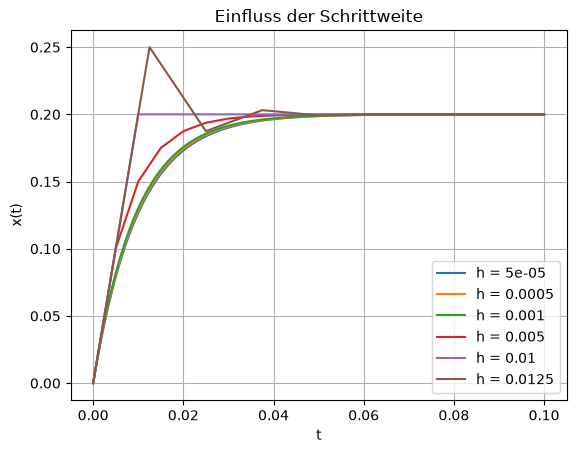

In [26]:
import matplotlib.pyplot as plt

h_values = [0.00005, 0.0005, 0.001, 0.005, 0.01, 0.0125]
# h_values = [0.001, 0.005, 0.01, 0.0125, 0.015, 0.0175, 0.019, 0.0195]
# h_values = [0.1]
t_end = 0.1
results = {}

for h in h_values:
    results[h] = solve(h, t_end)
    plt.plot(results[h]['t'], results[h]['x'], label=f'h = {h}')

plt.xlabel('t')
plt.ylabel('x(t)')
plt.title('Einfluss der Schrittweite')
plt.legend()
plt.grid()
plt.show()